# Fine-tune ViT5 và kết quả của run mới

Luồng huấn luyện chính: dữ liệu đã chuẩn bị → tokenizer/DataLoader → ViT5-Base → optimizer → từng epoch → validation → last/best → loss → sinh tóm tắt → so sánh greedy/beam trên validation.


### 1. Môi trường

In [1]:
from pathlib import Path
from google.colab import drive

resume_run_id = ""

drive.mount("/content/drive")
drive_root = Path("/content/drive/MyDrive/vietnamese-summarization")

if not drive_root.is_dir():
    raise RuntimeError("Lỗi: Không tìm thấy thư mục dự án trên Drive.")


Mounted at /content/drive


In [2]:
import os
import sys
import json
import subprocess

repo_url = "https://github.com/MD1809/vietnamese-summarization.git"
repo_dir = Path("/content/vietnamese-summarization")
target_commit = "b5cb961ed118f014d8fc4c5c5af607d429361949"

if not repo_dir.exists():
    subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True)

remote_result = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if remote_result.stdout.strip() != repo_url:
    raise RuntimeError("Lỗi: Repository không đúng dự án.")

status_result = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if status_result.stdout.strip() != "":
    raise RuntimeError("Lỗi: Repository còn thay đổi. Hãy dùng runtime mới.")

subprocess.run(["git", "fetch", "origin"], cwd=repo_dir, check=True)
subprocess.run(
    ["git", "checkout", "--detach", target_commit],
    cwd=repo_dir,
    check=True,
)

os.chdir(repo_dir)

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

print("Commit sử dụng:", target_commit)


Commit sử dụng: b5cb961ed118f014d8fc4c5c5af607d429361949


In [3]:
%pip uninstall -y -q diffusers torchvision timm fastai
%pip install -q "jedi==0.20.1"
%pip install -q -r /content/vietnamese-summarization/requirements.txt
%pip check


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
No broken requirements found.


In [4]:
import gc
import csv
import math
import time
import torch
import src.train
import src.tokenization
from src.utils import load_generation_config, load_train_config, set_seed

config_path = repo_dir / "configs" / "train.json"
train_config = load_train_config(config_path)
generation_config = load_generation_config(
    repo_dir / "configs" / "generation.json"
)

if not torch.cuda.is_available():
    raise RuntimeError("Lỗi: Cần GPU để chạy notebook huấn luyện.")

set_seed(train_config["seed"])

print(json.dumps(
    {
        "seed": train_config["seed"],
        "max_source_length": train_config["max_source_length"],
        "max_target_length": train_config["max_target_length"],
        "batch_size": train_config["batch_size"],
        "gradient_accumulation_steps": train_config["gradient_accumulation_steps"],
        "num_epochs": train_config["num_epochs"],
        "generation_config": generation_config,
    },
    ensure_ascii=False,
    indent=2,
))

print("GPU:", torch.cuda.get_device_name(0))


{
  "seed": 42,
  "max_source_length": 1024,
  "max_target_length": 128,
  "batch_size": 1,
  "gradient_accumulation_steps": 8,
  "num_epochs": 10,
  "generation_config": {
    "num_beams": 4,
    "max_new_tokens": 128,
    "do_sample": false
  }
}
GPU: Tesla T4


## 2. Dữ liệu, model và optimizer

In [5]:
tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
    config_path,
)

data_loaders = src.tokenization.create_train_validation_loaders(
    tokenized_splits,
    tokenizer,
    config_path,
)

print("Train:", len(tokenized_splits["train"]))
print("Validation:", len(tokenized_splits["validation"]))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Train: 2000
Validation: 201


In [6]:
set_seed(train_config["seed"])

if resume_run_id == "":
    run_profile = src.train.create_training_run(
        repo_dir,
        drive_root,
        allow_uncommitted=False,
    )
    model = src.train.load_vit5_model(config_path)
    optimizer = src.train.create_optimizer(model, config_path)
    progress = None
else:
    if Path(resume_run_id).name != resume_run_id or resume_run_id in [".", ".."]:
        raise RuntimeError("Lỗi: Run ID không được chứa đường dẫn.")

    profile_path = drive_root / "outputs" / resume_run_id / "config.json"
    run_profile = json.loads(profile_path.read_text(encoding="utf-8"))

    if run_profile["run_id"] != resume_run_id:
        raise RuntimeError("Lỗi: Hồ sơ không đúng run cần tiếp tục.")

    if run_profile["source"]["git_commit"] != target_commit:
        raise RuntimeError(
            "Lỗi: Resume cần đúng commit của run: "
            + run_profile["source"]["git_commit"]
        )

    model, tokenizer, optimizer, progress, resume_report = (
        src.train.load_last_checkpoint(
            run_profile["paths"]["checkpoint_dir"],
            data_loaders["train"],
            config_path,
        )
    )
    print("Epoch đã hoàn thành:", progress["completed_epochs"])
    print("Global step:", progress["global_step"])

print("Run huấn luyện:", run_profile["run_id"])

output_dir = Path(run_profile["paths"]["output_dir"])
checkpoint_dir = Path(run_profile["paths"]["checkpoint_dir"])
print("Output:", output_dir)
print("Checkpoint:", checkpoint_dir)


Run huấn luyện: vit5_finetuning_20261111_153238_146403
Output: /content/drive/MyDrive/vietnamese-summarization/outputs/vit5_finetuning_20261111_153238_146403
Checkpoint: /content/drive/MyDrive/vietnamese-summarization/checkpoints/vit5_finetuning_20261111_153238_146403


## 3. Vòng lặp epoch thực sự huấn luyện


In [7]:
if run_profile["train_config"] != train_config:
    raise RuntimeError("Lỗi: Cấu hình run không khớp cấu hình hiện tại.")

source_state, source_patch, source_snapshots = src.train.collect_run_source(
    repo_dir,
    allow_uncommitted=False,
)

if source_state["git_commit"] != run_profile["source"]["git_commit"]:
    raise RuntimeError("Lỗi: Phiên bản mã nguồn đã thay đổi.")

if run_profile["source_changes"]["patch_file"] is not None:
    raise RuntimeError("Lỗi: Run dùng bản vá phát triển; cần khôi phục đúng source trước khi resume.")

if run_profile["source_changes"]["untracked_snapshot_files"]:
    raise RuntimeError("Lỗi: Run dùng source snapshot; cần khôi phục đúng source trước khi resume.")

for name in ["last_pending", "last_previous", "best_pending", "best_previous"]:
    if (checkpoint_dir / name).exists():
        raise RuntimeError("Lỗi: Còn checkpoint tạm; cần kiểm tra trước khi huấn luyện.")

if progress is None:
    if (checkpoint_dir / "last").exists() or (checkpoint_dir / "best").exists():
        raise RuntimeError("Lỗi: Run mới không được dùng lại thư mục checkpoint cũ.")
    if len(optimizer.state) != 0 or (output_dir / "training_history.csv").exists():
        raise RuntimeError("Lỗi: Run mới cần optimizer và lịch sử mới.")
    progress = {"completed_epochs": 0, "global_step": 0, "training_history": []}

history = list(progress["training_history"])
completed_epochs = progress["completed_epochs"]
updates_per_epoch = (
    len(data_loaders["train"]) + train_config["gradient_accumulation_steps"] - 1
) // train_config["gradient_accumulation_steps"]

if len(history) != completed_epochs or not 0 <= completed_epochs <= train_config["num_epochs"]:
    raise RuntimeError("Lỗi: Lịch sử không khớp số epoch đã hoàn thành.")

if progress["global_step"] != completed_epochs * updates_per_epoch:
    raise RuntimeError("Lỗi: Global step không khớp tiến độ.")

for index, row in enumerate(history, 1):
    if row["epoch"] != index or row["global_step"] != index * updates_per_epoch:
        raise RuntimeError("Lỗi: Lịch sử epoch không liên tục.")

validation_ids = []

for sample in tokenized_splits["validation"]:
    validation_ids.append(sample["id"])

train_ids = []

for sample in tokenized_splits["train"]:
    train_ids.append(sample["id"])

if len(train_ids) != run_profile["data"]["train_sample_count"]:
    raise RuntimeError("Lỗi: Số mẫu train không khớp hồ sơ run.")

if len(validation_ids) != run_profile["data"]["validation_sample_count"]:
    raise RuntimeError("Lỗi: Số mẫu validation không khớp hồ sơ run.")

if set(train_ids).intersection(validation_ids):
    raise RuntimeError("Lỗi: Train và validation trùng ID.")

src.train.write_training_history(output_dir, history)
started_at = time.perf_counter()

for epoch_index in range(completed_epochs, train_config["num_epochs"]):
    print("Bắt đầu epoch:", epoch_index + 1, flush=True)

    training = src.train.train_epoch(
        model,
        data_loaders["train"],
        optimizer,
        progress["global_step"],
        config_path,
    )

    torch.cuda.synchronize()
    validation_started_at = time.perf_counter()
    validation = src.train.validate_model(model, data_loaders["validation"], validation_ids)
    torch.cuda.synchronize()
    validation_seconds = time.perf_counter() - validation_started_at

    if not math.isfinite(training["train_loss"]) or not math.isfinite(validation["validation_loss"]):
        raise RuntimeError("Lỗi: Loss không hữu hạn.")

    progress["completed_epochs"] = epoch_index + 1
    progress["global_step"] = training["global_step"]
    progress, best_decision = src.train.update_best_checkpoint(
        model, tokenizer, checkpoint_dir, progress, validation, config_path,
    )

    history.append({
        "epoch": epoch_index + 1,
        "global_step": training["global_step"],
        "train_loss": training["train_loss"],
        "validation_loss": validation["validation_loss"],
        "train_sample_count": training["train_sample_count"],
        "validation_sample_count": validation["sample_count"],
        "train_valid_target_tokens": training["train_valid_target_tokens"],
        "validation_valid_target_tokens": validation["valid_target_token_count"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_seconds": training["train_seconds"],
        "validation_seconds": validation_seconds,
        "epoch_compute_seconds": training["train_seconds"] + validation_seconds,
    })
    progress["training_history"] = list(history)

    src.train.save_last_checkpoint(
        model, tokenizer, optimizer, checkpoint_dir, progress,
        data_loaders["train"], config_path,
    )
    src.train.write_training_history(output_dir, history)

    print(
        "Epoch:", epoch_index + 1,
        "Train loss:", training["train_loss"],
        "Validation loss:", validation["validation_loss"],
        "Cập nhật best:", best_decision["updated"],
        flush=True,
    )

training_summary = {
    "run_id": run_profile["run_id"],
    "run_status": "completed",
    "completed_epochs": progress["completed_epochs"],
    "global_step": progress["global_step"],
    "history": history,
    "best_epoch": progress["best_epoch"],
    "best_global_step": progress["best_global_step"],
    "best_validation_loss": progress["best_validation_loss"],
    "checkpoint_dir": str(checkpoint_dir),
    "history_file": str(output_dir / "training_history.csv"),
    "current_invocation_seconds": time.perf_counter() - started_at,
    "resume_boundary": "end_of_epoch",
    "test_content_read": False,
    "training_entrypoint": "epoch loop in vietnamese_summarization_train.ipynb",
}

summary_path = output_dir / "training_summary.json"
summary_path.write_text(json.dumps(training_summary, ensure_ascii=False, indent=2), encoding="utf-8")

if json.loads(summary_path.read_text(encoding="utf-8")) != training_summary:
    raise RuntimeError("Lỗi: Summary đọc lại không khớp.")

del optimizer
del model
gc.collect()
torch.cuda.empty_cache()
print("Hoàn tất run:", training_summary["run_id"])
print("Best epoch:", training_summary["best_epoch"])
print("Best validation loss:", training_summary["best_validation_loss"])


Bắt đầu epoch: 1
Epoch: 1 Train loss: 2.399452931188972 Validation loss: 2.1208145915205816 Cập nhật best: True
Bắt đầu epoch: 2
Epoch: 2 Train loss: 1.8910314404399433 Validation loss: 2.102667951223594 Cập nhật best: True
Bắt đầu epoch: 3
Epoch: 3 Train loss: 1.567234576838114 Validation loss: 2.2157404929166975 Cập nhật best: False
Bắt đầu epoch: 4
Epoch: 4 Train loss: 1.310376215726069 Validation loss: 2.262776587113341 Cập nhật best: False
Bắt đầu epoch: 5
Epoch: 5 Train loss: 1.1041666812864115 Validation loss: 2.4256603391958818 Cập nhật best: False
Bắt đầu epoch: 6
Epoch: 6 Train loss: 0.9321037883594631 Validation loss: 2.6135998870607833 Cập nhật best: False
Bắt đầu epoch: 7
Epoch: 7 Train loss: 0.7938335899559148 Validation loss: 2.747354803315386 Cập nhật best: False
Bắt đầu epoch: 8
Epoch: 8 Train loss: 0.6792487350866091 Validation loss: 2.9245368596652455 Cập nhật best: False
Bắt đầu epoch: 9
Epoch: 9 Train loss: 0.5878346447411491 Validation loss: 3.045973490288563 Cập 

## 4. Loss và phân tích của chính run vừa chạy

In [8]:
report_run_id = run_profile["run_id"]
log_dir = output_dir

summary_path = log_dir / "training_summary.json"
history_path = log_dir / "training_history.csv"

analysis_summary = json.loads(summary_path.read_text(encoding="utf-8"))

if analysis_summary["run_id"] != report_run_id:
    raise RuntimeError("Lỗi: Summary không thuộc run cần phân tích.")

with history_path.open(encoding="utf-8", newline="") as history_file:
    history_rows = list(csv.DictReader(history_file))

if len(history_rows) != len(analysis_summary["history"]):
    raise RuntimeError("Lỗi: CSV và summary khác số epoch.")

for actual, expected in zip(history_rows, analysis_summary["history"]):
    for key in expected:
        if actual[key] != str(expected[key]):
            raise RuntimeError("Lỗi: CSV và summary không khớp tại " + key)

epochs = []
train_losses = []
validation_losses = []

for row in history_rows:
    epochs.append(int(row["epoch"]))
    train_losses.append(float(row["train_loss"]))
    validation_losses.append(float(row["validation_loss"]))

best_epoch = analysis_summary["best_epoch"]
best_loss = analysis_summary["best_validation_loss"]

if best_epoch not in epochs or best_loss != min(validation_losses):
    raise RuntimeError("Lỗi: Thông tin best không khớp lịch sử loss.")

if validation_losses[epochs.index(best_epoch)] != best_loss:
    raise RuntimeError("Lỗi: Best epoch không khớp validation loss.")

print("Run phân tích:", report_run_id)
print("Epoch | Train loss | Validation loss")

for index in range(len(epochs)):
    print(
        epochs[index],
        "|",
        format(train_losses[index], ".6f"),
        "|",
        format(validation_losses[index], ".6f"),
    )

print("Best epoch:", best_epoch)
print("Best validation loss:", best_loss)


Run phân tích: vit5_finetuning_20261111_153238_146403
Epoch | Train loss | Validation loss
1 | 2.399453 | 2.120815
2 | 1.891031 | 2.102668
3 | 1.567235 | 2.215740
4 | 1.310376 | 2.262777
5 | 1.104167 | 2.425660
6 | 0.932104 | 2.613600
7 | 0.793834 | 2.747355
8 | 0.679249 | 2.924537
9 | 0.587835 | 3.045973
10 | 0.517013 | 3.264683
Best epoch: 2
Best validation loss: 2.102667951223594


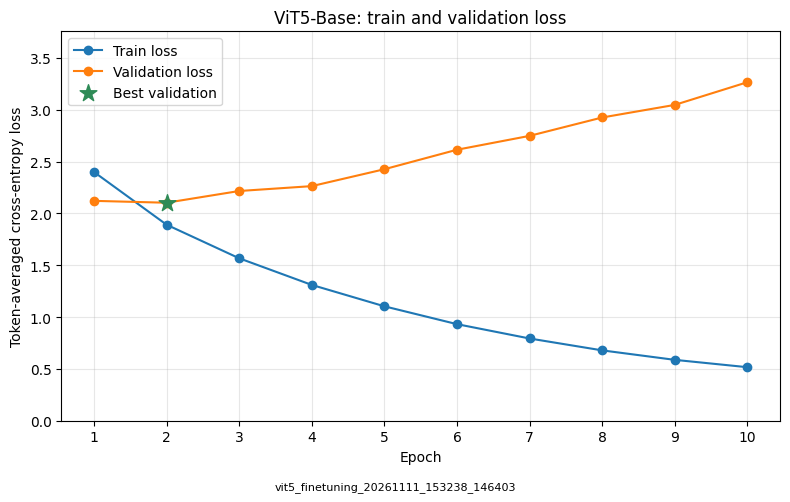

Biểu đồ: /content/drive/MyDrive/vietnamese-summarization/outputs/vit5_finetuning_20261111_153238_146403/figures/training_loss.png


In [9]:
import matplotlib.pyplot as plt

analysis_output_dir = output_dir
figure_dir = analysis_output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plot_path = figure_dir / "training_loss.png"

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, train_losses, marker="o", label="Train loss")
ax.plot(epochs, validation_losses, marker="o", label="Validation loss")
ax.scatter(
    [best_epoch],
    [best_loss],
    color="seagreen",
    marker="*",
    s=160,
    zorder=5,
    label="Best validation",
)

ax.set_title("ViT5-Base: train and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Token-averaged cross-entropy loss")
ax.set_xticks(epochs)
ax.set_ylim(0, max(train_losses + validation_losses) * 1.15)
ax.grid(True, alpha=0.3)
ax.legend()

fig.text(0.5, 0.01, report_run_id, ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(plot_path, dpi=200, facecolor="white")
plt.show()

print("Biểu đồ:", plot_path)


In [11]:
from google.colab import files

analysis_lines = [
    "# Phân tích kết quả huấn luyện",
    "",
    "- Run ID: " + report_run_id,
    "- Nguồn: training_history.csv và training_summary.json của đúng run.",
    "- Best epoch: " + str(best_epoch),
    "- Best global step: " + str(analysis_summary["best_global_step"]),
    "- Best validation loss: " + str(best_loss),
    "- Biểu đồ: [training_loss.png](figures/training_loss.png).",
    "",
    "| Epoch | Train loss | Validation loss |",
    "| --- | --- | --- |",
]

for index in range(len(epochs)):
    analysis_lines.append(
        "| " + str(epochs[index])
        + " | " + format(train_losses[index], ".6f")
        + " | " + format(validation_losses[index], ".6f") + " |"
    )

analysis_lines.append("")

if train_losses[-1] < train_losses[0] and validation_losses[-1] > best_loss:
    analysis_lines.append(
        "Train loss giảm nhưng validation loss ở epoch cuối cao hơn mức tốt nhất. "
        "Đây là dấu hiệu học quá sát train; giữ checkpoint có validation loss nhỏ nhất."
    )
else:
    analysis_lines.append(
        "Chọn checkpoint bằng validation loss nhỏ nhất trong các epoch đã lưu."
    )

analysis_lines.extend([
    "",
    "Loss được tổng hợp theo token đích hợp lệ, bỏ qua nhãn padding -100. "
    "Loss thấp không bảo đảm mọi bản tóm tắt đều đúng hoặc không lặp; "
    "đọc kết quả ROUGE và phân tích lỗi để đánh giá đầy đủ hơn.",
    "",
    "- Số liệu được tạo bởi luồng huấn luyện/resume của chính run này.",
    "- Bảng trên được tính từ log đã lưu, không thay đổi trọng số hoặc dữ liệu test.",
])

analysis_text = "\n".join(analysis_lines) + "\n"
analysis_path = analysis_output_dir / "training_analysis.md"
analysis_path.write_text(analysis_text, encoding="utf-8")

if analysis_path.read_text(encoding="utf-8") != analysis_text:
    raise RuntimeError("Lỗi: File phân tích đọc lại không khớp.")

print(analysis_text)
print("Phân tích:", analysis_path)

files.download(str(plot_path))
files.download(str(analysis_path))

files.download(str(history_path))
files.download(str(summary_path))


# Phân tích kết quả huấn luyện

- Run ID: vit5_finetuning_20261111_153238_146403
- Nguồn: training_history.csv và training_summary.json của đúng run.
- Best epoch: 2
- Best global step: 500
- Best validation loss: 2.102667951223594
- Biểu đồ: [training_loss.png](figures/training_loss.png).

| Epoch | Train loss | Validation loss |
| --- | --- | --- |
| 1 | 2.399453 | 2.120815 |
| 2 | 1.891031 | 2.102668 |
| 3 | 1.567235 | 2.215740 |
| 4 | 1.310376 | 2.262777 |
| 5 | 1.104167 | 2.425660 |
| 6 | 0.932104 | 2.613600 |
| 7 | 0.793834 | 2.747355 |
| 8 | 0.679249 | 2.924537 |
| 9 | 0.587835 | 3.045973 |
| 10 | 0.517013 | 3.264683 |

Train loss giảm nhưng validation loss ở epoch cuối cao hơn mức tốt nhất. Đây là dấu hiệu học quá sát train; giữ checkpoint có validation loss nhỏ nhất.

Loss được tổng hợp theo token đích hợp lệ, bỏ qua nhãn padding -100. Loss thấp không bảo đảm mọi bản tóm tắt đều đúng hoặc không lặp; đọc kết quả ROUGE và phân tích lỗi để đánh giá đầy đủ hơn.

- Số liệu được tạo

## 5. Tải best và sinh tóm tắt


In [12]:
from src.inference import load_summarizer, summarize_text

model, tokenizer, best_selection = load_summarizer(checkpoint_dir, config_path)

if best_selection["epoch"] != training_summary["best_epoch"]:
    raise RuntimeError("Lỗi: Best epoch không khớp run vừa huấn luyện.")
if best_selection["global_step"] != training_summary["best_global_step"]:
    raise RuntimeError("Lỗi: Best global step không khớp.")
if best_selection["validation_loss"] != training_summary["best_validation_loss"]:
    raise RuntimeError("Lỗi: Best loss không khớp.")

sample_text = (
    "Rửa sạch hạt đậu xanh rồi ngâm trong nước khoảng 8 giờ. "
    "Chuẩn bị chậu có lỗ thoát nước và đất tơi xốp. "
    "Gieo hạt, tưới nhẹ và đặt chậu ở nơi có ánh sáng. "
    "Giữ đất đủ ẩm nhưng tránh tưới quá nhiều."
)

sample_result = summarize_text(
    sample_text, model, tokenizer,
    config_path=config_path,
    generation_config_path=repo_dir / "configs" / "generation.json",
)

sample_report = {
    "run_id": run_profile["run_id"],
    "checkpoint": str(checkpoint_dir / "best"),
    "source": sample_text,
    "summary": sample_result["summary"],
    "generation_config": sample_result["generation_config"],
}
(output_dir / "sample_summary.json").write_text(
    json.dumps(sample_report, ensure_ascii=False, indent=2), encoding="utf-8",
)
print(json.dumps(sample_report, ensure_ascii=False, indent=2))

del model
gc.collect()
torch.cuda.empty_cache()


{
  "run_id": "vit5_finetuning_20261111_153238_146403",
  "checkpoint": "/content/drive/MyDrive/vietnamese-summarization/checkpoints/vit5_finetuning_20261111_153238_146403/best",
  "source": "Rửa sạch hạt đậu xanh rồi ngâm trong nước khoảng 8 giờ. Chuẩn bị chậu có lỗ thoát nước và đất tơi xốp. Gieo hạt, tưới nhẹ và đặt chậu ở nơi có ánh sáng. Giữ đất đủ ẩm nhưng tránh tưới quá nhiều.",
  "summary": "Rửa sạch hạt đậu xanh. Đặt chậu ở nơi có ánh sáng.",
  "generation_config": {
    "num_beams": 4,
    "max_new_tokens": 128,
    "do_sample": false
  }
}


## 6. So sánh greedy/beam trên validation của run mới


In [13]:
import src.evaluate

comparison_report = src.evaluate.run_decoding_comparison(
    project_root=repo_dir,
    drive_root=drive_root,
    checkpoint_run_id=run_profile["run_id"],
    config_path=config_path,
    generation_config_path=repo_dir / "configs" / "generation.json",
)

print("Run:", comparison_report["checkpoint_run_id"])
for method in ["greedy", "beam"]:
    candidate = comparison_report["candidates"][method]
    print(method, candidate["sample_count"], candidate["mean_f1_percent"])
print("Đề xuất từ validation:", comparison_report["proposed_method"])
print("Kết quả:", comparison_report["output_dir"])

gc.collect()
torch.cuda.empty_cache()


Chạy khởi động, không tính vào thời gian: greedy
Chạy khởi động, không tính vào thời gian: beam
Bắt đầu: greedy Số mẫu: 201
greedy ROUGE F1 x 100: {'rouge1': 23.5400511211901, 'rouge2': 10.695595832247408, 'rougeL': 20.995938269443304}
Bắt đầu: beam Số mẫu: 201
beam ROUGE F1 x 100: {'rouge1': 24.205816627553936, 'rouge2': 11.579471502252513, 'rougeL': 21.398286484115427}
Đã lưu báo cáo: /content/drive/MyDrive/vietnamese-summarization/outputs/decoding_comparison_20261111_171208_127089/decoding_comparison.json
Đề xuất: beam Chưa cập nhật generation.json.
Run: vit5_finetuning_20261111_153238_146403
greedy 201 {'rouge1': 23.5400511211901, 'rouge2': 10.695595832247408, 'rougeL': 20.995938269443304}
beam 201 {'rouge1': 24.205816627553936, 'rouge2': 11.579471502252513, 'rougeL': 21.398286484115427}
Đề xuất từ validation: beam
Kết quả: /content/drive/MyDrive/vietnamese-summarization/outputs/decoding_comparison_20261111_171208_127089


## 7. Test tùy chọn — sau khi chốt validation


In [15]:
evaluate_test = False
selected_method = ""

if evaluate_test:
    from datetime import datetime, timezone
    from src.baseline import summarize_lead_three
    from src.metrics import score_summaries

    if selected_method not in ["greedy", "beam"]:
        raise RuntimeError("Lỗi: Cần chốt greedy hoặc beam từ validation trước khi chạy test.")
    if comparison_report["checkpoint_run_id"] != run_profile["run_id"]:
        raise RuntimeError("Lỗi: Validation không thuộc run hiện tại.")

    selected_generation = comparison_report["candidates"][selected_method]["generation_config"]
    created_at = datetime.now(timezone.utc)
    test_dir = output_dir / ("test_evaluation_" + created_at.strftime("%Y%m%d_%H%M%S_%f"))
    test_dir.mkdir(parents=True, exist_ok=False)
    selected_generation_path = test_dir / "generation.json"
    selected_generation_path.write_text(
        json.dumps(selected_generation, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    decision = {
        "run_id": run_profile["run_id"],
        "comparison_id": comparison_report["comparison_id"],
        "selected_method": selected_method,
        "generation_config": selected_generation,
        "selection_basis": "user selection after validation; before reading test",
        "created_at_utc": created_at.isoformat(),
    }
    (test_dir / "decoding_selection.json").write_text(
        json.dumps(decision, ensure_ascii=False, indent=2), encoding="utf-8",
    )

    subset = json.loads(
        (drive_root / train_config["paths"]["subset_manifest"]).read_text(encoding="utf-8")
    )
    processed = json.loads(
        (drive_root / train_config["paths"]["processed_manifest"]).read_text(encoding="utf-8")
    )
    model, tokenizer, selection = load_summarizer(checkpoint_dir, config_path)

    if selection["epoch"] != comparison_report["best_epoch"]:
        raise RuntimeError("Lỗi: Best epoch khác lượt validation đã chốt.")
    if selection["global_step"] != comparison_report["best_global_step"]:
        raise RuntimeError("Lỗi: Best global step khác lượt validation đã chốt.")
    if selection["validation_loss"] != comparison_report["best_validation_loss"]:
        raise RuntimeError("Lỗi: Best loss khác lượt validation đã chốt.")

    rows, test_metadata = src.evaluate.load_fixed_test_source(
        drive_root,
        {"train_config": train_config, "subset": subset, "processed": processed},
    )
    set_seed(train_config["seed"])
    references = []
    baseline_predictions = []
    vit5_predictions = []
    records = []

    for index, row in enumerate(rows):
        baseline = summarize_lead_three(row["document"], tokenizer, config_path)
        vit5 = summarize_text(
            row["document"], model, tokenizer,
            config_path=config_path,
            generation_config_path=selected_generation_path,
        )
        if baseline["used_input_ids"] != vit5["used_input_ids"]:
            raise RuntimeError("Lỗi: Baseline và ViT5 không dùng cùng nguồn.")
        references.append(row["summary"])
        baseline_predictions.append(baseline["summary"])
        vit5_predictions.append(vit5["summary"])
        records.append({
            "id": row["id"], "source": row["document"], "reference": row["summary"],
            "baseline": baseline["summary"], "vit5": vit5["summary"],
        })
        if (index + 1) % 25 == 0 or index + 1 == len(rows):
            print("Đã xử lý test:", index + 1, "/", len(rows))

    results = {}
    for method, predictions in [("baseline", baseline_predictions), ("vit5", vit5_predictions)]:
        scores = score_summaries(references, predictions)
        results[method] = {
            "sample_count": scores["sample_count"],
            "mean_f1": scores["mean_f1"],
            "mean_f1_percent": scores["mean_f1_percent"],
        }

    test_report = {
        "run_id": run_profile["run_id"],
        "checkpoint": str(checkpoint_dir / "best"),
        "best_epoch": selection["epoch"],
        "best_global_step": selection["global_step"],
        "best_validation_loss": selection["validation_loss"],
        "train_config": train_config,
        "generation_config": selected_generation,
        "decision": decision,
        "test_metadata": test_metadata,
        "metric_settings": scores["settings"],
        "results": results,
        "test_previously_inspected_in_project": True,
        "test_used_for_tuning_this_run": False,
    }
    with (test_dir / "predictions.jsonl").open("w", encoding="utf-8") as prediction_file:
        for record in records:
            prediction_file.write(json.dumps(record, ensure_ascii=False) + "\n")
    (test_dir / "metrics.json").write_text(
        json.dumps(test_report, ensure_ascii=False, indent=2), encoding="utf-8",
    )
    print(json.dumps(results, ensure_ascii=False, indent=2))
    print("Kết quả test của run mới:", test_dir)

    del model
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("Test chưa được chạy. Hoàn tất và chốt validation trước khi bật evaluate_test.")


Test chưa được chạy. Hoàn tất và chốt validation trước khi bật evaluate_test.
